# Task 2 – 150 Daily Mirror sentences, tagged by hand with the Penn Treebank tag set

**Source:** Daily Mirror (Sri Lanka) online news, <https://www.dailymirror.lk>. The article URLs and access dates are listed in `task2_sources.txt`.

**Procedure**
1. 150 sentences of reasonable length (at least 8 tokens each) were copied from recent news articles into `task2_raw_sentences.txt`, one per line.
2. Each sentence is **tokenised with the Penn Treebank conventions** so its tokens line up with the training corpus. Clitics are split (`won't` → `wo n't`, `Lanka's` → `Lanka 's`), punctuation is separated, `"` becomes the opening/closing quote tokens `` `` `` and `''`, and brackets become `-LRB-`/`-RRB-`.
3. The tokens are written to a tagging sheet (`task2_tagging_sheet.xlsx` / `.csv`). **Every tag was assigned manually by the annotator**, using the course's Penn Treebank tag sheet; no automatic tagger was used, as the brief requires. That sheet uses the TreeTagger spelling of the PTB tags (NP, NPS, PP, PPZ, SENT, VV\*/VH\*). On export these are mapped one-to-one to the original PTB spelling used in the NLTK training corpus (NNP, NNPS, PRP, PRP$, `.`, VB\*), in the column `tag_ptb`. Punctuation, determiners *the/a/an*, *to*, plain numbers and *Rs.* follow fixed PTB rules; they were pre-filled by rule and then checked by the annotator.
4. The completed sheet is validated (every tag must be a legal PTB tag, and no token may be left untagged) and exported as the final submission file, `task2_150_tagged_sentences.csv` (plus a `word/TAG` text version).

*Optional:* if a second person also tags the sheet (column `tag_annotator2`), Cohen's κ between the two annotators is reported.

In [1]:
import os, re, collections, unicodedata
import pandas as pd
import matplotlib.pyplot as plt
from nltk.tokenize import TreebankWordTokenizer

RAW_FILE   = "task2_raw_sentences.txt"      # one sentence per line (input)
SHEET_CSV  = "task2_tagging_sheet.csv"      # token sheet you fill in
SHEET_XLSX = "task2_tagging_sheet.xlsx"
FINAL_CSV  = "task2_150_tagged_sentences.csv"
FINAL_TXT  = "task2_150_tagged_sentences.txt"
N_EXPECTED, MIN_TOKENS = 150, 8

PTB_TAGS = ["CC","CD","DT","EX","FW","IN","JJ","JJR","JJS","LS","MD","NN","NNS","NNP","NNPS","PDT","POS","PRP","PRP$",
            "RB","RBR","RBS","RP","SYM","TO","UH","VB","VBD","VBG","VBN","VBP","VBZ","WDT","WP","WP$","WRB",
            "#","$",".",",",":","``","''","-LRB-","-RRB-"]

## 1. Tokenise the raw sentences and create the tagging sheet

This step runs only if no tagging sheet exists yet, so your finished tags are never overwritten.

In [2]:
def normalise(text):
    # web text uses curly quotes, dashes and non-breaking spaces; map them to ASCII PTB-style forms
    text = unicodedata.normalize("NFKC", text)
    for a, b in {"‘": "'", "’": "'", "“": '"', "”": '"', "–": "--", "—": "--", " ": " "}.items():
        text = text.replace(a, b)
    return re.sub(r"\s+", " ", text).strip()

tok = TreebankWordTokenizer()
def ptb_tokenise(sentence):
    return tok.tokenize(normalise(sentence), convert_parentheses=True)

if os.path.exists(SHEET_CSV) or os.path.exists(SHEET_XLSX):
    print("Tagging sheet already exists: not regenerated (delete it to start again).")
elif not os.path.exists(RAW_FILE):
    print(f"Put your 150 Daily Mirror sentences in {RAW_FILE} (one per line) and re-run this cell.")
else:
    raw = [l.strip() for l in open(RAW_FILE, encoding="utf-8") if l.strip()]
    rows = []
    for sid, s in enumerate(raw, 1):
        for tid, w in enumerate(ptb_tokenise(s), 1):
            rows.append({"sent_id": sid, "token_id": tid, "token": w, "tag": "", "tag_annotator2": "",
                         "sentence": normalise(s) if tid == 1 else ""})
    sheet = pd.DataFrame(rows)
    sheet.to_csv(SHEET_CSV, index=False)
    sheet.to_excel(SHEET_XLSX, index=False)
    print(f"{len(raw)} sentences -> {len(sheet)} tokens written to {SHEET_XLSX} and {SHEET_CSV}")

Tagging sheet already exists: not regenerated (delete it to start again).


### Tagging guide (quick reference)

| Tag | Use | Tag | Use |
|---|---|---|---|
| NN / NNS | common noun sing. / plural | VB | base form (*to **go***, *will **go***) |
| NNP / NNPS | proper noun sing. / plural (*Sri*, *Lanka*, *Colombo*) | VBD | past tense (*said*) |
| PRP / PRP$ | *he, it* / *his, its* | VBN | past participle (*was **arrested***) |
| DT | *the, a, this, all* | VBG | *-ing* verb (*is **rising***) |
| IN | preposition / subordinator (*of, in, that, because*) | VBZ / VBP | present *has, says* / *have, say* |
| JJ / JJR / JJS | adjective / *-er* / *-est* | MD | *will, can, should* |
| RB | adverb (*also, not, n't*) | TO | *to* (always) |
| CD | numbers (*150*, *five*, *2026*) | POS | possessive *'s* |
| CC | *and, or, but* | RP | particle (*set **up***) |
| WDT / WP / WRB | *which / who / when, where* | punctuation | `, . : `` '' -LRB- -RRB- $` |

*Rs.* (rupees) is tagged `$`, as for `US$` in the treebank; *Mr.* is NNP; the *to* of the infinitive and the preposition are both TO.

## 2. Load and validate the completed sheet

In [3]:
src = SHEET_XLSX if os.path.exists(SHEET_XLSX) else SHEET_CSV
sheet = pd.read_excel(src, dtype=str, keep_default_na=False) if src.endswith("xlsx") else pd.read_csv(src, dtype=str, keep_default_na=False)
sheet["sent_id"] = sheet.sent_id.astype(int); sheet["token_id"] = sheet.token_id.astype(int)
sheet["tag"] = sheet.tag.str.strip()
# The course tag sheet ("Penn-TreeBank" tab) uses the TreeTagger variant of the PTB tag set
# (NP, PP, PPZ, SENT, VV*/VH*). These map one-to-one onto the original PTB tags used in the
# NLTK treebank, so either spelling is accepted and converted here.
VARIANT = {"NP": "NNP", "NPS": "NNPS", "PP": "PRP", "PPZ": "PRP$", "PP$": "PRP$", "SENT": ".", "IN/that": "IN",
           "VV": "VB", "VVD": "VBD", "VVG": "VBG", "VVN": "VBN", "VVP": "VBP", "VVZ": "VBZ",
           "VH": "VB", "VHD": "VBD", "VHG": "VBG", "VHN": "VBN", "VHP": "VBP", "VHZ": "VBZ",
           "(": "-LRB-", ")": "-RRB-", "\u201c": "``", "\u201d": "''"}
sheet["tag_course"] = sheet.tag                      # tags exactly as annotated (course tag sheet)
converted = sheet.tag.isin(VARIANT).sum()
sheet["tag"] = sheet.tag.replace(VARIANT)             # original PTB spelling, used by the model
if "tag_annotator2" in sheet:
    sheet["tag_annotator2"] = sheet.tag_annotator2.astype(str).str.strip().replace(VARIANT)
if converted: print(f"Mapped {converted} course-sheet (TreeTagger-style) tags to original PTB spelling")
sheet = sheet.sort_values(["sent_id", "token_id"]).reset_index(drop=True)
print("Read", src, "->", sheet.sent_id.nunique(), "sentences,", len(sheet), "tokens")

problems = []
missing = sheet[sheet.tag == ""]
invalid = sheet[(sheet.tag != "") & ~sheet.tag.isin(PTB_TAGS)]
lengths = sheet.groupby("sent_id").size()
if len(missing): problems.append(f"{len(missing)} tokens have no tag, e.g. sentences {sorted(missing.sent_id.unique())[:10]}")
if len(invalid): problems.append(f"{len(invalid)} tokens have a tag outside the PTB set: {sorted(invalid.tag.unique())}")
if sheet.sent_id.nunique() != N_EXPECTED: problems.append(f"expected {N_EXPECTED} sentences, found {sheet.sent_id.nunique()}")
short = lengths[lengths < MIN_TOKENS]
if len(short): problems.append(f"{len(short)} sentences shorter than {MIN_TOKENS} tokens: {list(short.index)}")

print("\n".join("PROBLEM: " + p for p in problems) if problems else "All checks passed.")
display(invalid.head(20)) if len(invalid) else None

Mapped 1253 course-sheet (TreeTagger-style) tags to original PTB spelling
Read task2_tagging_sheet.xlsx -> 150 sentences, 4237 tokens
All checks passed.


In [4]:
# Consistency checks for obvious slips. These only compare against fixed PTB rules; they never suggest a tag for an open-class word.
fixed = {",": ",", ".": ".", "?": ".", "!": ".", ":": ":", ";": ":", "--": ":", "``": "``", "''": "''",
         "-LRB-": "-LRB-", "-RRB-": "-RRB-", "to": "TO", "To": "TO", "$": "$", "#": "#"}
slip = sheet[sheet.token.isin(fixed) & (sheet.tag != "") & (sheet.token.map(fixed) != sheet.tag)]
num_slip = sheet[sheet.token.str.fullmatch(r"[\d.,/]+\d") & (sheet.tag != "") & (sheet.tag != "CD")]
print(f"Punctuation / 'to' slips: {len(slip)}   Numbers not tagged CD: {len(num_slip)}")
pd.concat([slip, num_slip])[["sent_id", "token_id", "token", "tag"]]

Punctuation / 'to' slips: 0   Numbers not tagged CD: 0


,sent_id,token_id,token,tag


## 3. Inter-annotator agreement (optional)

In [5]:
from sklearn.metrics import cohen_kappa_score
both = sheet[(sheet.tag != "") & (sheet.get("tag_annotator2", "").astype(str).str.strip() != "")] if "tag_annotator2" in sheet else sheet.iloc[0:0]
if len(both) > 0:
    k = cohen_kappa_score(both.tag, both.tag_annotator2.str.strip())
    agree = (both.tag == both.tag_annotator2.str.strip()).mean()
    print(f"Doubly-annotated tokens: {len(both)}  raw agreement: {agree:.3f}  Cohen's kappa: {k:.3f}")
else:
    print("No second annotation supplied: all tags come from a single annotator.")

No second annotation supplied: all tags come from a single annotator.


## 4. Export the final tagged sentences (submission file) and corpus profile

In [6]:
assert not (len(missing) or len(invalid)), "Fix the missing/invalid tags listed in Section 2 before exporting."
final = sheet[["sent_id", "token_id", "token", "tag_course", "tag"]].rename(columns={"tag_course": "tag_as_annotated", "tag": "tag_ptb"})
final.to_csv(FINAL_CSV, index=False)
final.to_excel(FINAL_CSV.replace(".csv", ".xlsx"), index=False)   # Excel copy (the lecturer asked for an Excel sheet)
with open(FINAL_TXT, "w", encoding="utf-8") as f:
    for sid, g in final.groupby("sent_id"):
        f.write(f"{sid}\t" + " ".join(f"{w}/{t}" for w, t in zip(g.token, g.tag_as_annotated)) + "\n")
print(f"Wrote {FINAL_CSV}, {FINAL_CSV.replace('.csv', '.xlsx')} and {FINAL_TXT}")
print(open(FINAL_TXT, encoding="utf-8").read()[:1200])

Wrote task2_150_tagged_sentences.csv, task2_150_tagged_sentences.xlsx and task2_150_tagged_sentences.txt
1	Excessive/JJ screen/NN use/NN among/IN preschool/NN children/NNS is/VBZ raising/VVG concerns/NNS over/IN their/PPZ brain/NN development/NN ,/, language/NN and/CC social/JJ skills/NNS ,/, physical/JJ activity/NN and/CC overall/JJ health/NN ,/, with/IN 64/CD %/NN of/IN children/NNS spending/VVG more/JJR than/IN 30/CD minutes/NNS a/DT day/NN on/IN screens/NNS ,/, according/VVG to/TO a/DT recent/JJ survey/NN conducted/VVN by/IN the/DT Health/NP Promotion/NP Bureau/NP in/IN collaboration/NN with/IN the/DT University/NP of/IN Colombo/NP and/CC UNICEF/NP ./SENT
2	The/DT figures/NNS were/VBD highlighted/VVN by/IN Dr/NP Anil/NP Jasinghe/NP ,/, Secretary/NP to/TO the/DT Ministry/NP of/IN Health/NP and/CC Mass/NP Media/NP ,/, at/IN a/DT media/NN briefing/NN ./SENT
3	The/DT survey/NN ,/, conducted/VVD across/IN four/CD provinces/NNS -/: Southern/NP ,/, Western/JJ ,/, Central/JJ and/CC Norther

,value
sentences,150.00
tokens,4237.00
mean tokens/sentence,28.25
min,9.00
max,63.00
distinct tags used,45.00


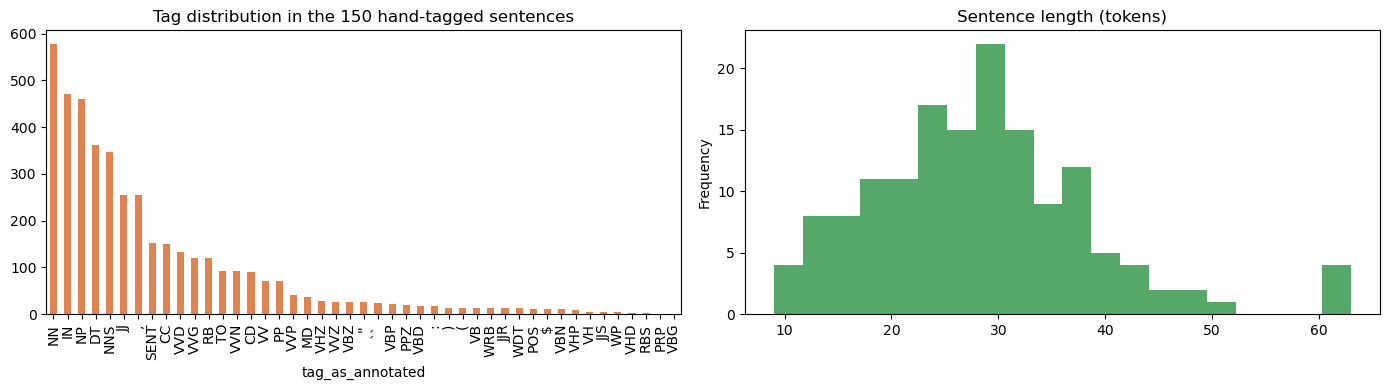

In [7]:
stats = pd.Series({"sentences": final.sent_id.nunique(), "tokens": len(final),
                   "mean tokens/sentence": lengths.mean(), "min": lengths.min(), "max": lengths.max(),
                   "distinct tags used": final.tag_as_annotated.nunique()}).round(2)
display(stats.to_frame("value"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
final.tag_as_annotated.value_counts().plot.bar(ax=ax[0], color="#DD8452", title="Tag distribution in the 150 hand-tagged sentences")
lengths.plot.hist(bins=20, ax=ax[1], color="#55A868", title="Sentence length (tokens)")
plt.tight_layout(); plt.savefig("task2_profile.png", dpi=120); plt.show()